### EXPERIMENT 1: MANUAL GLOBAL THRESHOLDING

Objective: Segment objects using manually selected intensity thresholds.

Tasks:
 1. Examine the image histogram.
 2. Apply different threshold values.
 3. Compare the resulting binary masks.

Question: How does threshold selection affect object segmentation?


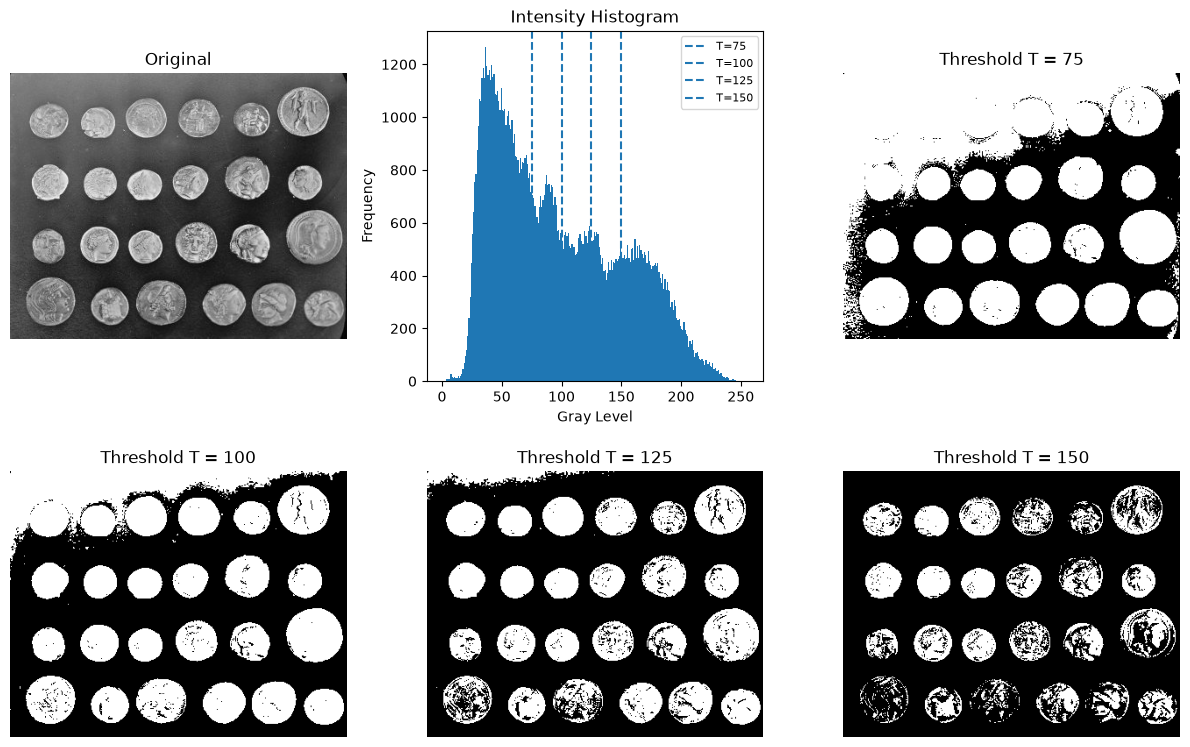

In [1]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.coins()

thresholds = [75, 100, 125, 150]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

axes[0, 1].hist(img.ravel(), bins=256, range=(0, 256))
axes[0, 1].set_title("Intensity Histogram")
axes[0, 1].set_xlabel("Gray Level")
axes[0, 1].set_ylabel("Frequency")

for T in thresholds:
    axes[0, 1].axvline(T, linestyle="--", label=f"T={T}")

axes[0, 1].legend(fontsize=8)

for ax, T in zip(axes.flat[2:], thresholds):
    binary = img > T

    ax.imshow(binary, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Threshold T = {T}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 2: ITERATIVE GLOBAL THRESHOLDING

Objective: Implement automatic threshold selection using group means.

Tasks:
 1. Initialize the threshold.
 2. Partition pixels into two groups.
 3. Update the threshold until convergence.
 4. Visualize the threshold evolution.

Question: Why does the algorithm require a convergence criterion?



Final threshold: 107.45
Iterations: 7


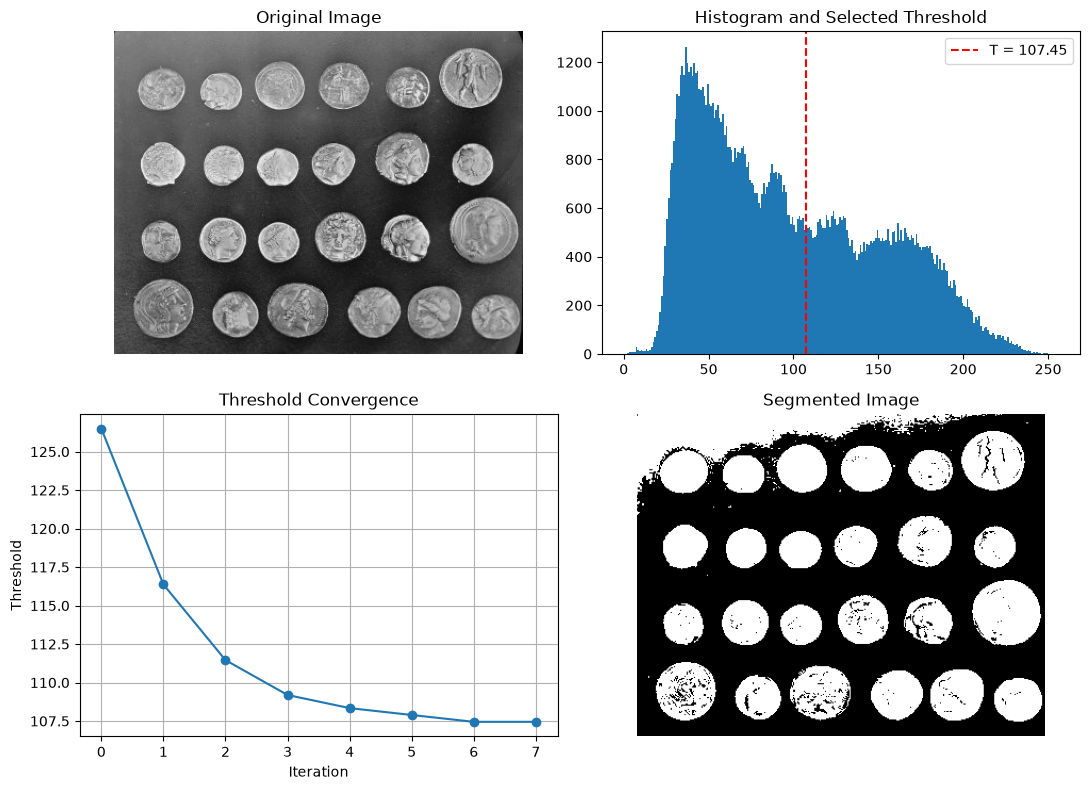

In [2]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.coins().astype(float)

T = (img.min() + img.max()) / 2
tolerance = 0.01
history = [T]

for iteration in range(100):
    G1 = img[img > T]
    G2 = img[img <= T]

    if G1.size == 0 or G2.size == 0:
        break

    T_new = (G1.mean() + G2.mean()) / 2
    history.append(T_new)

    if abs(T_new - T) < tolerance:
        T = T_new
        break

    T = T_new

binary = img > T

print(f"Final threshold: {T:.2f}")
print(f"Iterations: {len(history) - 1}")

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")

axes[0, 1].hist(img.ravel(), bins=256, range=(0, 256))
axes[0, 1].axvline(T, color="red", linestyle="--",
                   label=f"T = {T:.2f}")
axes[0, 1].set_title("Histogram and Selected Threshold")
axes[0, 1].legend()

axes[1, 0].plot(history, marker="o")
axes[1, 0].set_title("Threshold Convergence")
axes[1, 0].set_xlabel("Iteration")
axes[1, 0].set_ylabel("Threshold")
axes[1, 0].grid(True)

axes[1, 1].imshow(binary, cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title("Segmented Image")

axes[0, 0].axis("off")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 3: OTSU'S THRESHOLDING

Objective: Compare manual, iterative, and Otsu threshold selection.

Tasks:
 1. Apply three global thresholding methods.
 2. Compare their thresholds and segmentation masks.
 3. Examine the selected thresholds on the histogram.

Question: Under what image conditions might Otsu's method fail?



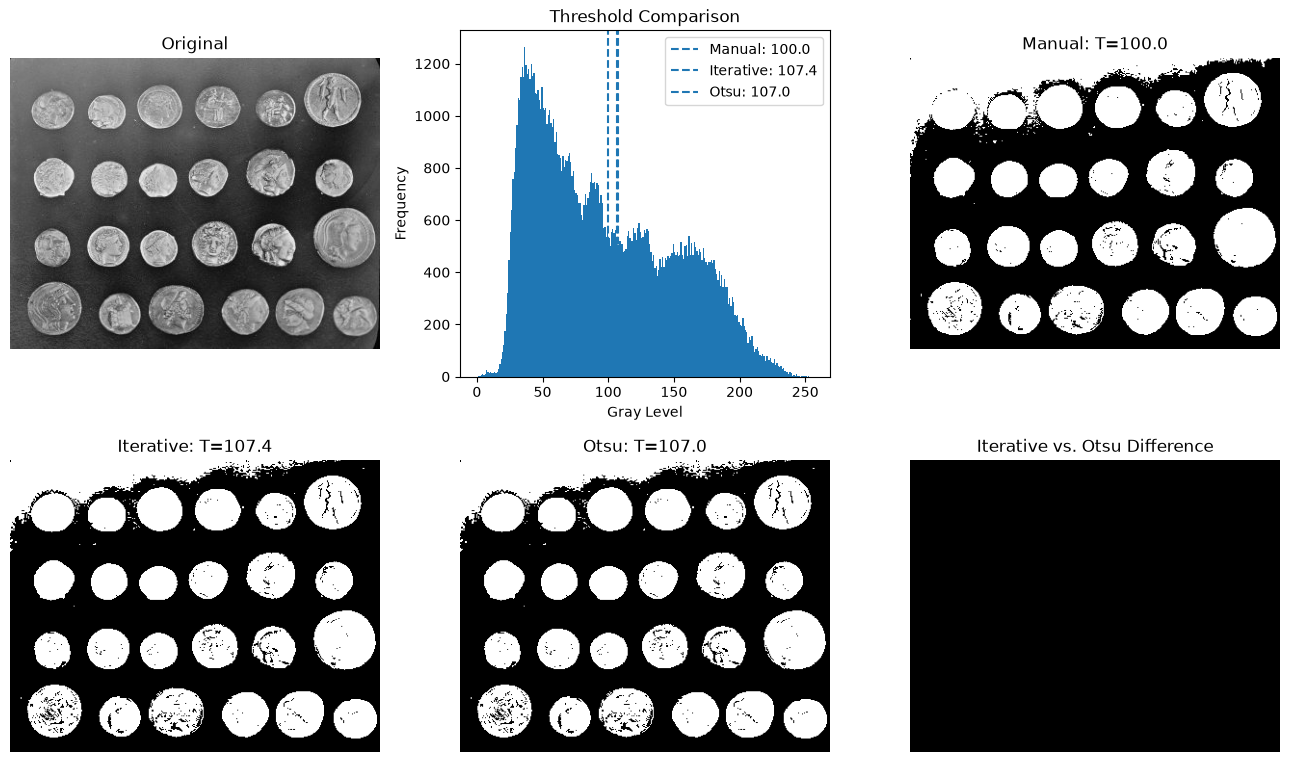

In [3]:
from skimage import data, filters
import numpy as np
import matplotlib.pyplot as plt

img = data.coins()

T_manual = 100
T_iterative = float(T)  # From Experiment 2
T_otsu = filters.threshold_otsu(img)

thresholds = [T_manual, T_iterative, T_otsu]
names = ["Manual", "Iterative", "Otsu"]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

# Original image
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

# Histogram with selected thresholds
axes[0, 1].hist(img.ravel(), bins=256, range=(0, 256))

for name, threshold in zip(names, thresholds):
    axes[0, 1].axvline(
        threshold, linestyle="--",
        label=f"{name}: {threshold:.1f}"
    )

axes[0, 1].set_title("Threshold Comparison")
axes[0, 1].set_xlabel("Gray Level")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].legend()

# Segmentation results
for ax, name, threshold in zip(
    [axes[0, 2], axes[1, 0], axes[1, 1]],
    names, thresholds
):
    ax.imshow(img > threshold, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{name}: T={threshold:.1f}")
    ax.axis("off")

# Difference between iterative and Otsu segmentation
difference = (img > T_iterative) != (img > T_otsu)

axes[1, 2].imshow(difference, cmap="gray", vmin=0, vmax=1)
axes[1, 2].set_title("Iterative vs. Otsu Difference")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 4: LOCAL ADAPTIVE THRESHOLDING

Objective: Compare global and local thresholding under uneven illumination.

Tasks:
 1. Generate an image with nonuniform illumination.
 2. Apply Otsu global thresholding.
 3. Apply local adaptive thresholding.
 4. Visualize the spatial threshold map.

Question: Why can local thresholding outperform global thresholding?


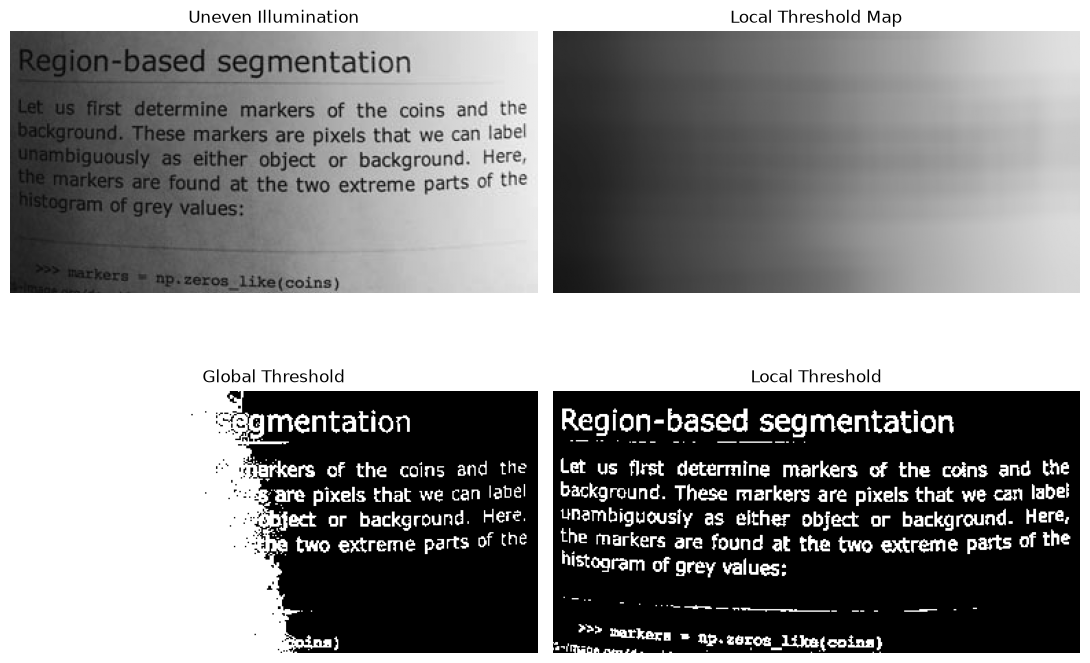

In [21]:
from skimage import data, filters
import numpy as np
import matplotlib.pyplot as plt

img = data.page().astype(float)

# Simulate a horizontal illumination gradient
illumination = np.linspace(0.45, 1.0, img.shape[1])
uneven = np.clip(img * illumination[None, :], 0, 255)

T_global = filters.threshold_otsu(uneven)
global_mask = uneven < T_global

# Local mean-based thresholding
T_local = filters.threshold_local(
    uneven, block_size=51, method="mean", offset=10
)
local_mask = uneven < T_local

images = [
    uneven, T_local,
    global_mask, local_mask
]

titles = [
    "Uneven Illumination", "Local Threshold Map",
    "Global Threshold", "Local Threshold"
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, image, title in zip(axes.flat, images, titles):
    if "Threshold" in title and title != "Local Threshold Map":
        ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


### EXPERIMENT 5: REGION GROWING FROM SCRATCH

Objective: Implement seed-based region growing using intensity similarity.

Tasks:
 1. Select a seed pixel.
 2. Evaluate neighboring pixels using a homogeneity criterion.
 3. Expand the region until no more pixels satisfy the criterion.

Question: How does the region mean influence subsequent pixel inclusion?


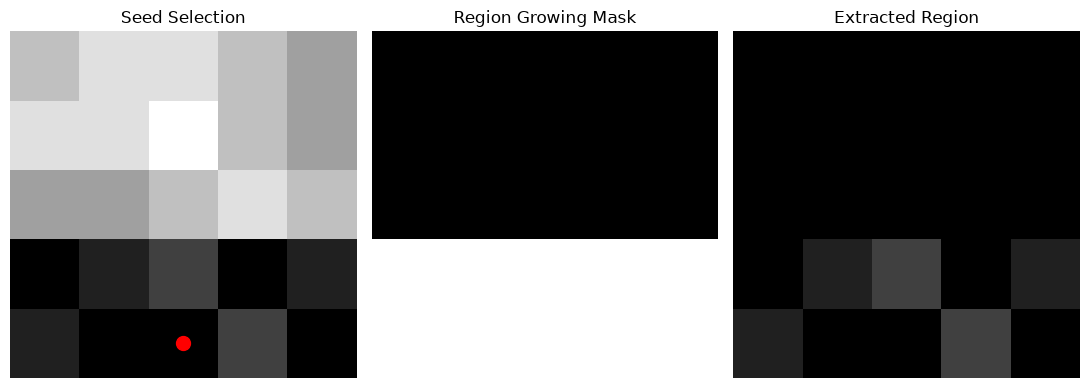

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

img = np.array([
    [6, 7, 7, 6, 5],
    [7, 7, 8, 6, 5],
    [5, 5, 6, 7, 6],
    [0, 1, 2, 0, 1],
    [1, 0, 0, 2, 0]
], dtype=float)

seed = (4, 2)
delta = 3

def region_growing(image, seed, delta, connectivity=4):
    H, W = image.shape
    mask = np.zeros((H, W), dtype=bool)
    visited = np.zeros((H, W), dtype=bool)

    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    if connectivity == 8:
        neighbors += [
            (-1, -1), (-1, 1),
            (1, -1), (1, 1)
        ]

    queue = deque([seed])
    visited[seed] = True
    mask[seed] = True

    region_sum = float(image[seed])
    region_size = 1

    while queue:
        y, x = queue.popleft()

        for dy, dx in neighbors:
            ny, nx = y + dy, x + dx

            if not (0 <= ny < H and 0 <= nx < W):
                continue

            if visited[ny, nx]:
                continue

            mean = region_sum / region_size

            if abs(image[ny, nx] - mean) <= delta:
                visited[ny, nx] = True
                mask[ny, nx] = True
                queue.append((ny, nx))

                region_sum += image[ny, nx]
                region_size += 1

    return mask

mask = region_growing(img, seed, delta)

fig, axes = plt.subplots(1, 3, figsize=(11, 4))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=8)
axes[0].scatter(seed[1], seed[0], c="red", s=100)
axes[0].set_title("Seed Selection")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Region Growing Mask")

axes[2].imshow(img * mask, cmap="gray", vmin=0, vmax=8)
axes[2].set_title("Extracted Region")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 6: REGION GROWING SENSITIVITY

Objective: Investigate seed selection, similarity threshold, and connectivity.

Tasks:
 1. Apply region growing using different delta values.
 2. Compare 4-connectivity and 8-connectivity.
 3. Observe changes in segmented region size.

Question: Why can different seeds produce different segmentations?


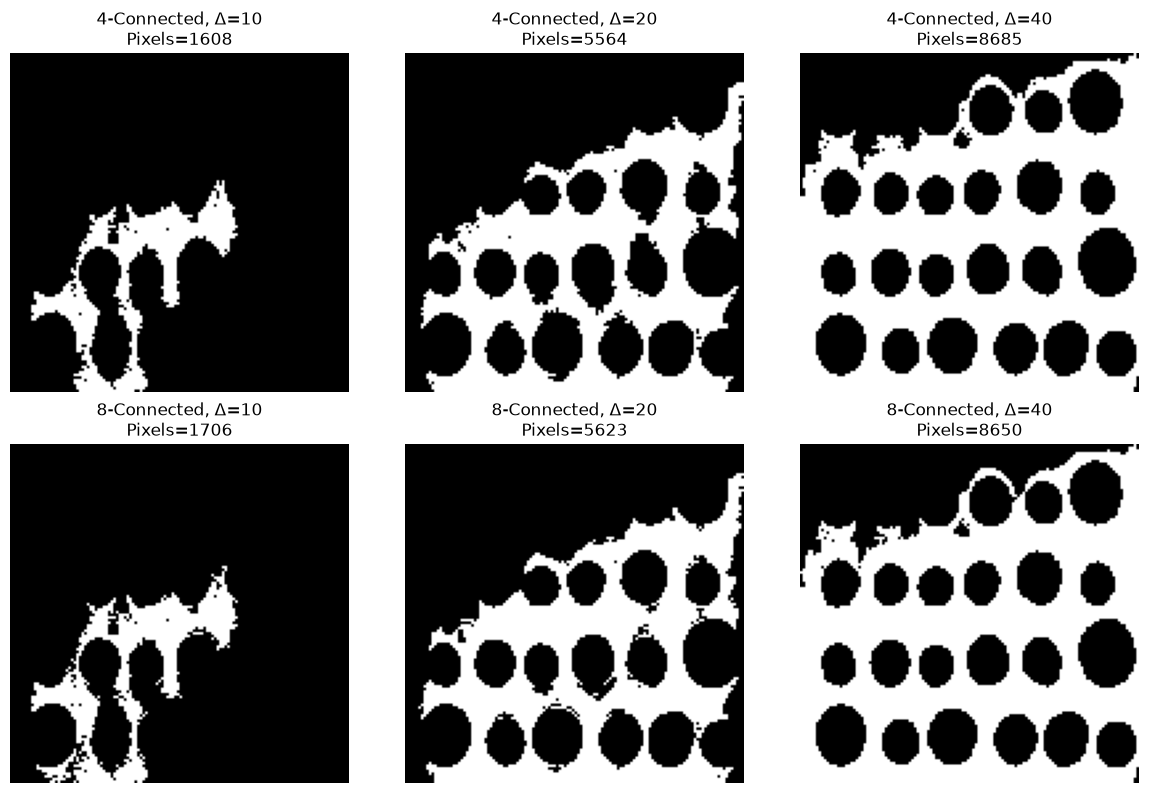

In [23]:
from skimage import data, transform
import numpy as np
import matplotlib.pyplot as plt

img = transform.resize(
    data.coins(), (128, 128),
    preserve_range=True, anti_aliasing=True
)

seed = (64, 64)
deltas = [10, 20, 40]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, connectivity in enumerate([4, 8]):
    for j, delta in enumerate(deltas):
        mask = region_growing(
            img, seed, delta,
            connectivity=connectivity
        )

        axes[i, j].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(
            f"{connectivity}-Connected, Δ={delta}\n"
            f"Pixels={mask.sum()}"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 7: REGION SPLITTING

Objective: Implement recursive quadtree splitting.

Tasks:
 1. Define a homogeneity criterion based on standard deviation.
 2. Recursively split nonhomogeneous regions.
 3. Visualize the resulting quadtree partitions.

Question: How does the homogeneity threshold affect partition size?


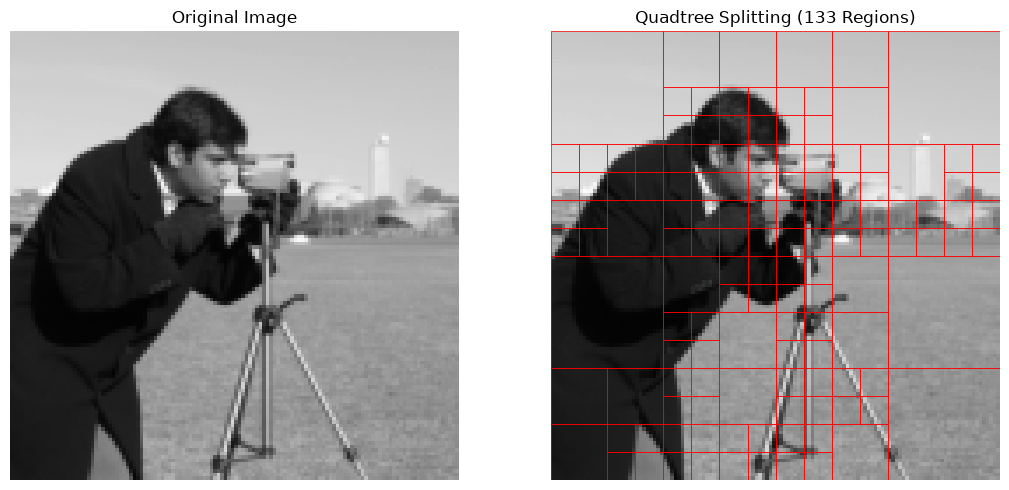

In [28]:
from skimage import data, transform
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

img = transform.resize(
    data.camera(), (128, 128),
    preserve_range=True, anti_aliasing=True
)

tau = 15
min_size = 8

regions = []

def split_region(image, y, x, size):
    block = image[y:y+size, x:x+size]

    if block.std() <= tau or size <= min_size:
        regions.append((y, x, size))
        return

    half = size // 2

    for dy in [0, half]:
        for dx in [0, half]:
            split_region(image, y+dy, x+dx, half)

split_region(img, 0, 0, img.shape[0])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(img, cmap="gray", vmin=0, vmax=255)

for y, x, size in regions:
    rect = Rectangle(
        (x-0.5, y-0.5), size, size,
        fill=False, edgecolor="red", linewidth=0.5
    )
    axes[1].add_patch(rect)

axes[1].set_title(f"Quadtree Splitting ({len(regions)} Regions)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 8: REGION SPLITTING AND MERGING

Objective: Merge adjacent quadtree regions based on homogeneity.

Tasks:
 1. Generate quadtree partitions.
 2. Identify adjacent regions.
 3. Merge regions satisfying a combined homogeneity criterion.
 4. Visualize the final labeled segmentation.

Question: Why must adjacency be considered during region merging?


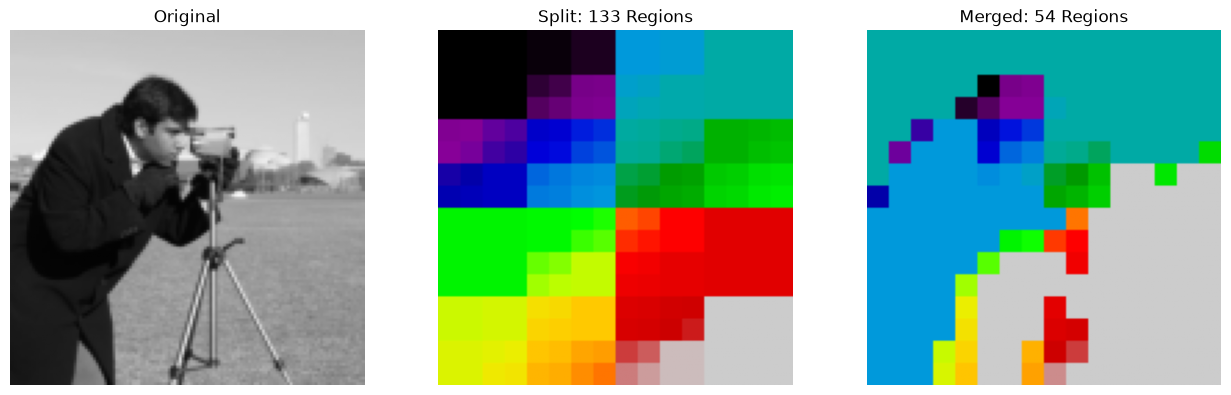

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import color
from scipy.ndimage import label as connected_label

# Use the image and quadtree regions from Experiment 7
# Create a label map for the quadtree leaves
labels = np.zeros(img.shape, dtype=np.int32)

for k, (y, x, size) in enumerate(regions, start=1):
    labels[y:y+size, x:x+size] = k

# Region adjacency: horizontal and vertical boundaries
def adjacent_pairs(label_map):
    pairs = set()

    for a, b in [
        (label_map[:, :-1], label_map[:, 1:]),
        (label_map[:-1, :], label_map[1:, :])
    ]:
        boundary = (a != b)

        for u, v in zip(a[boundary], b[boundary]):
            pairs.add(tuple(sorted((int(u), int(v)))))

    return sorted(pairs)

# Union-find structure for merged regions
parent = {int(k): int(k) for k in np.unique(labels)}

def find(k):
    while parent[k] != k:
        parent[k] = parent[parent[k]]
        k = parent[k]
    return k

def merge(a, b):
    parent[find(b)] = find(a)

# Repeatedly merge adjacent regions if their union is homogeneous
while True:
    changed = False

    for a, b in adjacent_pairs(labels):
        ra, rb = find(a), find(b)

        if ra == rb:
            continue

        mask = np.isin(
            labels,
            [k for k in parent if find(k) in (ra, rb)]
        )

        if img[mask].std() <= tau:
            merge(ra, rb)
            changed = True
            break

    if not changed:
        break

# Reconstruct merged labels
merged_labels = np.zeros_like(labels)

for k in np.unique(labels):
    merged_labels[labels == k] = find(int(k))

_, merged_labels = np.unique(
    merged_labels, return_inverse=True
)
merged_labels = merged_labels.reshape(img.shape)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")

axes[1].imshow(labels, cmap="nipy_spectral")
axes[1].set_title(f"Split: {len(np.unique(labels))} Regions")

axes[2].imshow(merged_labels, cmap="nipy_spectral")
axes[2].set_title(
    f"Merged: {len(np.unique(merged_labels))} Regions"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()